In [1]:
print("hi")

hi


In [8]:
from IPython.display import Image, display
from pydantic import BaseModel
from langgraph.graph import StateGraph, START, END
from typing import List,Optional

In [10]:
# state definition
class AgentState(BaseModel):
    values:List[int]
    name:str
    result: Optional[int] = None

In [18]:
# build node
def sum_node(state:AgentState):
    """A node that sums the values in the input state and updates the result"""
    state.result = state.name + " total sum is: "+ str(sum(state.values))
    return state

In [19]:
# garph with state
graph=StateGraph(AgentState)

# adding node to graph
graph.add_node("summation_node",sum_node)

# add edges to nodes
graph.add_edge(START,"summation_node")
graph.add_edge("summation_node",END)

# compile graph
agent=graph.compile()


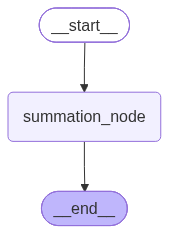

In [20]:
display(Image(agent.get_graph().draw_mermaid_png()))

In [23]:
response=agent.invoke({"name":"sai","values":[10,23,45]})
response["result"]


'sai total sum is: 78'